# Model training and local inference times

This notebook combines two different sources. YOLO **training duration** is the cumulative time recorded in `models/yolov26*/results.csv` during the original training runs. RF-DETR logs contain validation metrics for epochs 40–49, but no training duration. These files do not contain inference latency.

**Inference latency** is measured on the machine running this notebook, using locally available checkpoints. Saved outputs are historical until the corresponding cells are run again. Do not compare training duration with local inference latency as though they were recorded in the same experiment.


## Generate charts from saved results

This cell checks the recorded samples and generates training duration and inference latency charts. Training durations come from the original training logs. Inference latencies come from the saved benchmark JSON. The charts are exported as 300 dpi PNGs and PDFs in `notebooks/generated/figures/`.

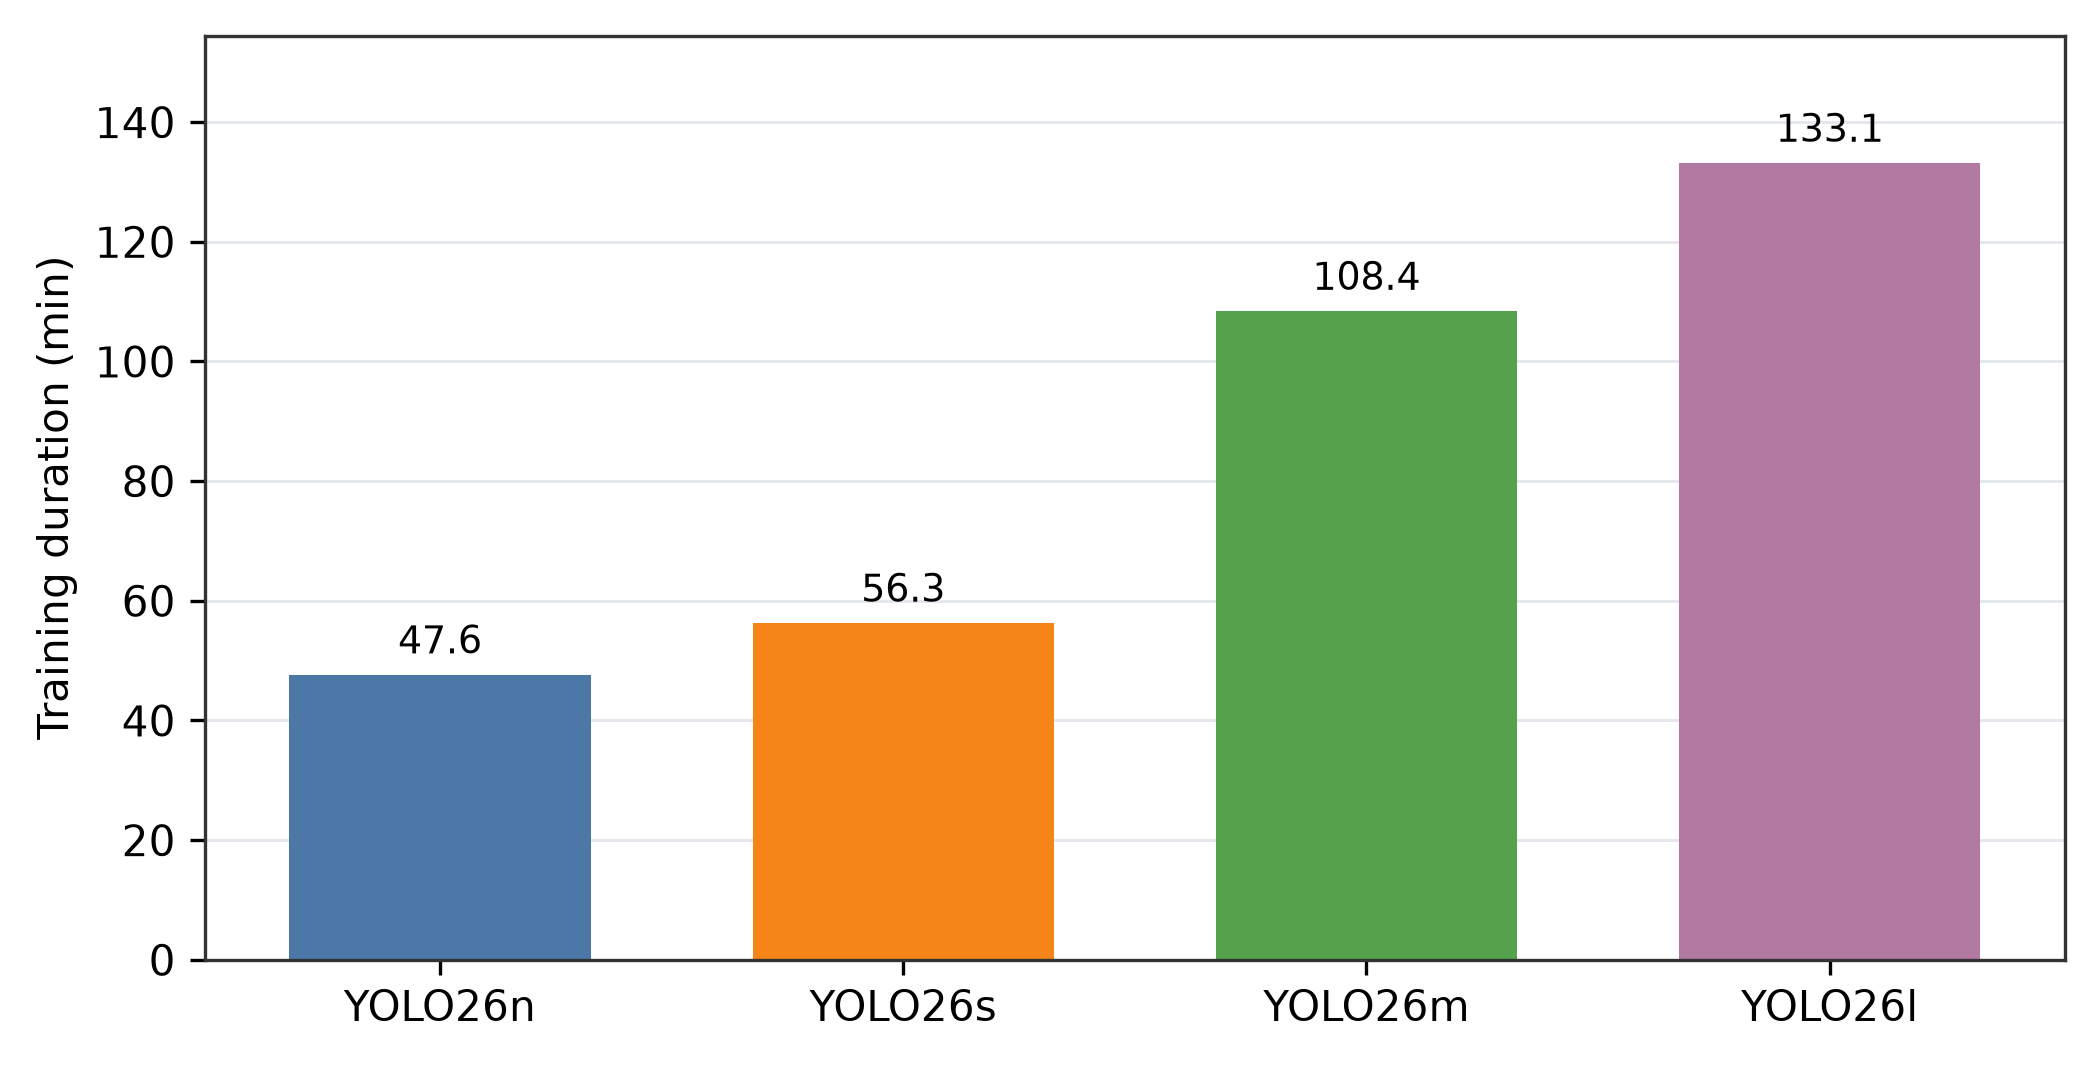

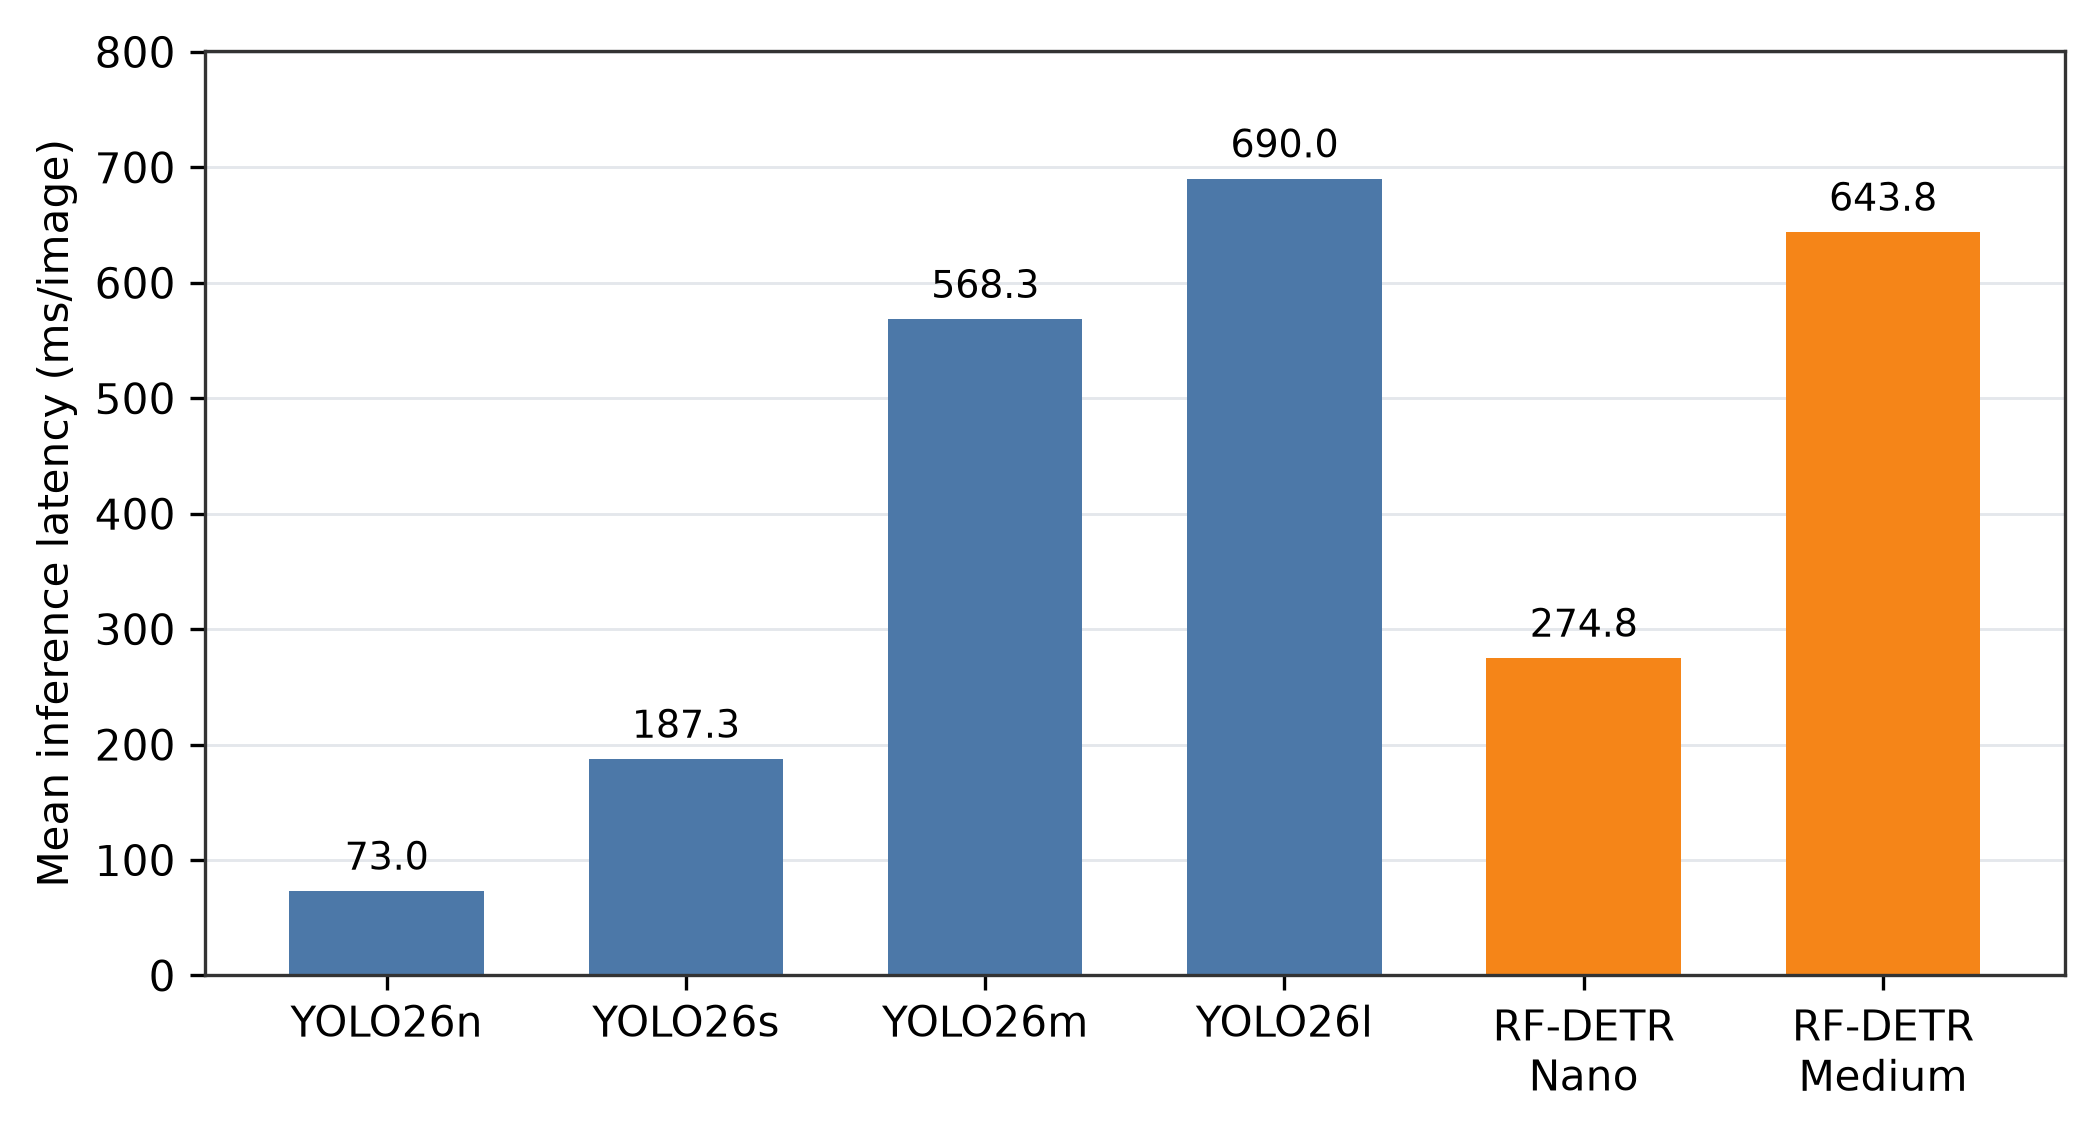

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'dataset/data.yaml').exists())
sys.path.insert(0, str(project_root / 'src'))
from evaluation.plotting.timing_figures import generate
result = generate()
for filename in ('tempo_treinamento_yolo26.png', 'tempo_inferencia_cpu.png'):
    display(Image(filename=str(project_root / 'notebooks/generated/figures' / filename), width=800))

In [2]:
from pathlib import Path
import csv
import json
import platform
import statistics
import time

import cv2
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from ultralytics import YOLO
import yaml

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models").is_dir() and (p / "dataset").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the urban-disaster-monitor repository.")
MODELS_DIR = PROJECT_ROOT / "models"
with (PROJECT_ROOT / "dataset" / "data.yaml").open() as file:
    dataset_config = yaml.safe_load(file)
CLASS_NAMES = dataset_config["names"]
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[i] for i in sorted(CLASS_NAMES)]
print(f"Project: {PROJECT_ROOT}")
print(f"Python: {platform.python_version()} | PyTorch: {torch.__version__}")

Project: /home/carol/urban-disaster-monitor
Python: 3.12.3 | PyTorch: 2.14.1+cu130


## Training information available in the artifacts

For YOLO, `training_time_s` is the final cumulative `time` value in `results.csv` from the original training run. `seconds_per_epoch` is an average of that total, not a separately logged duration for each epoch. The logs do not identify the exact training hardware. For RF-DETR, `metrics.csv` supplies only the epochs represented in the preserved file (currently 40–49 for both variants), while `training_config.json` supplies the planned epoch count and saved device setting; neither records training duration. A saved device setting does not establish the machine used in every session.


In [3]:
def find_weights(model_dir):
    if model_dir.name.startswith("yolo"):
        path = model_dir / "weights" / "best.pt"
        return path if path.is_file() else None
    direct = model_dir / "checkpoint_best_total.pth"
    if direct.is_file():
        return direct
    cache = PROJECT_ROOT / "app" / "models"
    candidates = sorted(cache.glob(
        f"models--carolinasoares--urban-disaster-{model_dir.name}/snapshots/*/checkpoint_best_total.pth"
    ))
    return candidates[-1] if candidates else None

training_records = []
for model_dir in sorted(p for p in MODELS_DIR.iterdir()
                        if p.is_dir() and (p.name.startswith("yolov26") or p.name.startswith("rfdetr"))):
    name = model_dir.name
    weights = find_weights(model_dir)
    record = {
        "model": name,
        "family": "YOLO" if name.startswith("yolo") else "RF-DETR",
        "logged_epochs": None,
        "training_time_s": None,
        "training_time_min": None,
        "seconds_per_epoch": None,
        "weights_available": weights is not None,
        "weights_source": str(weights.relative_to(PROJECT_ROOT)) if weights else None,
        "training_source": "not recorded",
    }
    results_csv = model_dir / "results.csv"
    metrics_csv = model_dir / "metrics.csv"
    if results_csv.is_file():
        with results_csv.open(newline="") as file:
            rows = list(csv.DictReader(file))
        if rows:
            record["logged_epochs"] = int(rows[-1]["epoch"])
            times = [float(row["time"]) for row in rows if row.get("time")]
            if times:
                seconds = times[-1]
                record["training_time_s"] = seconds
                record["training_time_min"] = seconds / 60
                record["seconds_per_epoch"] = seconds / len(times)
                record["training_source"] = str(results_csv.relative_to(PROJECT_ROOT))
    elif metrics_csv.is_file():
        with metrics_csv.open(newline="") as file:
            rows = list(csv.DictReader(file))
        epochs = sorted({int(row["epoch"]) for row in rows if row.get("val/mAP_50")})
        if epochs:
            record["logged_epochs"] = len(epochs)
            record["first_logged_epoch"] = epochs[0]
            record["last_logged_epoch"] = epochs[-1]
        config = model_dir / "training_config.json"
        if config.is_file():
            saved_config = json.loads(config.read_text())
            record["planned_epochs"] = saved_config["train_config"].get("epochs")
            record["configured_device"] = saved_config["model_config"].get("device")
    training_records.append(record)

training = pd.DataFrame(training_records)
print("YOLO — recorded training time")
display(training[training.family == "YOLO"].round(2))
print("RF-DETR — duration not recorded")
display(training[training.family == "RF-DETR"].round(2))

YOLO — recorded training time


,model,family,logged_epochs,training_time_s,training_time_min,seconds_per_epoch,weights_available,weights_source,training_source,first_logged_epoch,last_logged_epoch,planned_epochs,configured_device
2,yolov26l,YOLO,50,7987.20,133.12,159.74,True,models/yolov26l/weights/best.pt,models/yolov26l/results.csv,NaN,NaN,NaN,NaN
3,yolov26m,YOLO,50,6502.50,108.38,130.05,True,models/yolov26m/weights/best.pt,models/yolov26m/results.csv,NaN,NaN,NaN,NaN
4,yolov26n,YOLO,50,2857.05,47.62,57.14,True,models/yolov26n/weights/best.pt,models/yolov26n/results.csv,NaN,NaN,NaN,NaN
5,yolov26s,YOLO,50,3375.18,56.25,67.50,True,models/yolov26s/weights/best.pt,models/yolov26s/results.csv,NaN,NaN,NaN,NaN


RF-DETR — duration not recorded


,model,family,logged_epochs,training_time_s,training_time_min,seconds_per_epoch,weights_available,weights_source,training_source,first_logged_epoch,last_logged_epoch,planned_epochs,configured_device
0,rfdetrmedium,RF-DETR,10,NaN,NaN,NaN,True,app/models/models--carolinasoares--urban-disas...,not recorded,40.0,49.0,50.0,cuda
1,rfdetrnano,RF-DETR,10,NaN,NaN,NaN,True,app/models/models--carolinasoares--urban-disas...,not recorded,40.0,49.0,50.0,mps


## Local inference benchmark

The benchmark uses the same first `IMAGE_COUNT` validation images for every model, repeated `REPEATS` times. Images, weights, and warmup are loaded before timing. Each timed `predict` call includes preprocessing, network execution, and postprocessing; it excludes file reading, weight loading, warmup, and box drawing. YOLO uses `imgsz=640`; RF-DETR uses its configured resolution. The model families have different preprocessing, so cross-family latency comparisons remain exploratory.

`BENCHMARK_DEVICE` defaults to CPU. Change it explicitly for CUDA or MPS. A new benchmark replaces `models/comparisons/model-inference-times.json` **only when all expected models are measured successfully**. A missing checkpoint or error leaves the current file intact. A complete new run also stores the individual timing samples and environment metadata. Saved outputs below can reflect an earlier run of the code.


In [4]:
IMAGE_COUNT = 10
WARMUP = 3
REPEATS = 3
IMGSZ = 640

BENCHMARK_DEVICE = "cpu"  # Change to 0 (CUDA) or "mps" only when intended.
if BENCHMARK_DEVICE == 0:
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA was requested but is not available")
    DEVICE = 0
    HARDWARE = torch.cuda.get_device_name(0)
elif BENCHMARK_DEVICE == "mps":
    if not hasattr(torch.backends, "mps") or not torch.backends.mps.is_available():
        raise RuntimeError("MPS was requested but is not available")
    DEVICE = "mps"
    HARDWARE = "Apple MPS"
elif BENCHMARK_DEVICE == "cpu":
    DEVICE = "cpu"
    HARDWARE = platform.processor() or platform.machine()
else:
    raise ValueError("BENCHMARK_DEVICE must be 'cpu', 'mps', or 0")

def synchronize():
    if DEVICE == 0:
        torch.cuda.synchronize()
    elif DEVICE == "mps":
        torch.mps.synchronize()

images_dir = PROJECT_ROOT / "dataset" / "valid" / "images"
image_files = sorted(p for p in images_dir.iterdir()
                     if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})[:IMAGE_COUNT]
images = [cv2.imread(str(p)) for p in image_files]
if not images or any(image is None for image in images):
    raise ValueError(f"Could not load images from {images_dir}")
print(f"Device: {DEVICE} ({HARDWARE}) | Images: {len(images)}")
print(f"Planned samples per model: {len(images) * REPEATS}")

Device: cpu (x86_64) | Images: 10
Planned samples per model: 30


In [ ]:
inference_records = []
for row in training_records:
    name = row["model"]
    family = row["family"]
    weights = find_weights(MODELS_DIR / name)
    if weights is None:
        inference_records.append({"model": name, "family": family, "status": "no local checkpoint"})
        print(f"{name}: no local checkpoint; skipped")
        continue
    model = None
    try:
        if family == "YOLO":
            model = YOLO(str(weights))
            resolution = IMGSZ
            def predict(image):
                return model.predict(image, imgsz=IMGSZ, device=DEVICE,
                                     verbose=False, save=False)
            inputs = images  # OpenCV BGR arrays, as expected by Ultralytics.
        else:
            from rfdetr import RFDETRNano, RFDETRMedium
            model_class = RFDETRNano if name.endswith("nano") else RFDETRMedium
            config = json.loads((MODELS_DIR / name / "training_config.json").read_text())
            resolution = config["model_config"]["resolution"]
            model = model_class(pretrain_weights=str(weights),
                                num_classes=len(CLASS_NAMES) + 1,
                                resolution=resolution,
                                device="cuda:0" if DEVICE == 0 else DEVICE)
            def predict(image):
                return model.predict(image, threshold=0.25)
            inputs = [cv2.cvtColor(image, cv2.COLOR_BGR2RGB) for image in images]
        for i in range(WARMUP):
            predict(inputs[i % len(inputs)])
        synchronize()
        samples_ms = []
        for _ in range(REPEATS):
            for image in inputs:
                synchronize()
                start = time.perf_counter()
                predict(image)
                synchronize()
                samples_ms.append((time.perf_counter() - start) * 1000)
        mean_ms = statistics.fmean(samples_ms)
        inference_records.append({
            "model": name, "family": family, "status": "measured",
            "device": str(DEVICE), "hardware": HARDWARE,
            "images": len(images), "samples": len(samples_ms),
            "resolution": resolution, "mean_ms": mean_ms,
            "median_ms": statistics.median(samples_ms),
            "p95_ms": float(np.percentile(samples_ms, 95)),
            "images_per_second": 1000 / mean_ms,
            "samples_ms": samples_ms,
            "checkpoint": str(weights.relative_to(PROJECT_ROOT)),
        })
        print(f"{name}: {mean_ms:.1f} ms/image ({len(samples_ms)} samples)")
    except Exception as exc:
        inference_records.append({"model": name, "family": family,
                                  "status": f"error: {type(exc).__name__}: {exc}"})
        print(f"{name}: error: {exc}")
    finally:
        if model is not None:
            del model
        if DEVICE == 0:
            torch.cuda.empty_cache()

inference = pd.DataFrame(inference_records)
print("YOLO — local inference")
display(inference[inference.family == "YOLO"].drop(columns="samples_ms", errors="ignore").round(2))
print("RF-DETR — local inference")
display(inference[inference.family == "RF-DETR"].drop(columns="samples_ms", errors="ignore").round(2))

benchmark_path = MODELS_DIR / "comparisons" / "model-inference-times.json"
if inference_records and all(row["status"] == "measured" for row in inference_records):
    from datetime import datetime, timezone
    from importlib.metadata import version
    benchmark_path.parent.mkdir(parents=True, exist_ok=True)
    benchmark = {
        "source": "notebooks/evaluation/performance/model-training-inference-times.ipynb local benchmark",
        "measured_at_utc": datetime.now(timezone.utc).isoformat(),
        "device": str(DEVICE), "hardware": HARDWARE,
        "platform": platform.platform(),
        "python_version": platform.python_version(),
        "torch_version": torch.__version__,
        "ultralytics_version": version("ultralytics"),
        "rfdetr_version": version("rfdetr"),
        "torch_num_threads": torch.get_num_threads(),
        "images": len(images),
        "image_files": [str(path.relative_to(PROJECT_ROOT)) for path in image_files],
        "warmup_calls_per_model": WARMUP, "repeats": REPEATS,
        "samples_per_model": len(images) * REPEATS,
        "timing_scope": "predict call; includes preprocessing, network, and postprocessing; excludes image loading, model loading, warmup, and drawing",
        "models": {row["model"]: {key: row[key] for key in
            ("family", "resolution", "mean_ms", "median_ms", "p95_ms", "samples_ms", "checkpoint")}
            for row in inference_records},
    }
    benchmark_path.write_text(json.dumps(benchmark, indent=2) + "\n")
    print(f"Saved complete local inference benchmark: {benchmark_path}")
else:
    failed = [f"{row['model']}: {row['status']}" for row in inference_records
              if row["status"] != "measured"]
    print(f"Incomplete benchmark; JSON left unchanged: {benchmark_path}")
    print("Missing or failed models:", "; ".join(failed))


## Summary by model family

YOLO training durations come from the original logs; RF-DETR training duration is unavailable, and only validation epochs 40–49 survive in the current RF-DETR CSV files. Inference times come from the local benchmark in this kernel session. Saved outputs can reflect an older execution and should be refreshed after code changes.


In [ ]:
summary = training.merge(inference.drop(columns="family"), on="model", how="left")
columns = ["model", "logged_epochs", "training_time_min", "mean_ms",
           "median_ms", "p95_ms", "images_per_second", "resolution",
           "device", "samples", "status"]
print("YOLO")
display(summary.loc[summary.family == "YOLO", columns].round(2))
print("RF-DETR")
display(summary.loc[summary.family == "RF-DETR", columns].round(2))

# Uncomment to save measurements from this machine:
# summary.to_csv(PROJECT_ROOT / "notebooks" / "model-timings-local.csv", index=False)